> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 📘 Lesson 16: Classification Showdown
*Six algorithms, one loan-approval problem, one fair tournament, and a decision you can defend*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~130 min | 🟠 Intermediate | Lessons 09–15 |

---
## 🎬 The Hook
You now know six classifiers. Each one has strengths, quirks and a loyal following. A bank asks the practical question: *"We receive thousands of loan applications. Which model should pre-screen them, and where should we draw the line between 'approve' and 'send to a human'?"*

Answering it properly means running a **fair tournament** (so no model is advantaged), looking at **more than accuracy**, checking whether the **probabilities** can be trusted, and: most importantly: translating the **business costs** into the decision threshold. That's what separates a notebook exercise from a deployable decision.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Design a fair classifier tournament: shared preprocessing, identical stratified folds, several metrics, a baseline, fair tuning, and a single final test.
2. Compare Logistic Regression, Decision Tree, Random Forest, KNN, Naive Bayes and SVM on accuracy, ROC-AUC, F1, PR-AUC, log loss and speed.
3. Plot ROC curves and compare probability quality (calibration).
4. Turn a business **cost matrix** into a decision threshold chosen with cross-validated predictions, and measure the money saved on the test set.
5. Use a decision guide to select an algorithm from the data's characteristics and the business constraints.

## 🗺️ Roadmap

- Rules of the tournament
- Round 1: defaults (CV)
- Round 2: tuned
- The final: held-out test + ROC curves
- Can we trust the probabilities?
- From costs to a threshold (and the savings)
- Decision guide
- Problems & quiz

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
import time, warnings
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, average_precision_score, log_loss, roc_curve, confusion_matrix, precision_score, recall_score)
from sklearn.calibration import calibration_curve
warnings.filterwarnings("ignore")

Setup complete ✅


---
## 📜 1. Rules of the tournament

1. **One locked test set** (25 %), stratified on the target; never used for selection.
2. **One preprocessing recipe** inside a `Pipeline` (impute → scale numbers, impute → one-hot categories): identical for every model.
3. **Identical stratified 5-fold CV** for all models; report mean ± std.
4. **Several metrics**: accuracy, ROC-AUC (ranking), F1 (hard decisions), PR-AUC, log loss (probability quality), fit time.
5. **A baseline** (`DummyClassifier(strategy='prior')`: always predicts the majority class, with the class share as its probability) so we know what 'nothing' scores.
6. **Comparable tuning budgets** for every contestant.
7. **Business costs decide the threshold**, not 0.5.

We use the loan-approval data. We keep out `loan_id` (an identifier) and `interest_rate_offered`, plus the sensitive attributes `gender` and `married`: Project 3 explains why.

In [2]:
loans = pd.read_csv(data_path("loan_approval.csv"))
loans["emi"] = loans["loan_amount_kes"] / loans["loan_term_months"] * 1.15
loans["dti"] = (loans["monthly_debt_kes"] + loans["emi"]) / loans["monthly_income_kes"]
loans["lti"] = loans["loan_amount_kes"] / (loans["monthly_income_kes"] * 12)
loans["log_income"] = np.log(loans["monthly_income_kes"]); loans["log_savings"] = np.log1p(loans["savings_balance_kes"])

num_cols = ["credit_score", "credit_history_years", "dti", "lti", "log_income", "log_savings", "has_collateral", "age", "dependents", "existing_loans"]
cat_cols = ["employment_type", "property_area", "education"]
X, y = loans[num_cols + cat_cols], loans["approved"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("train:", Xtr.shape, "| test (locked):", Xte.shape, "| approval rate:", round(y.mean(), 3))

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
def build(est): return Pipeline([("prep", preprocess), ("model", est)])

cv = StratifiedKFold(5, shuffle=True, random_state=0)
scoring = {"accuracy": "accuracy", "roc_auc": "roc_auc", "f1": "f1", "pr_auc": "average_precision", "neg_log_loss": "neg_log_loss"}

train: (2250, 13) | test (locked): (750, 13) | approval rate: 0.604


---
## 🥊 2. The contestants and Round 1 (default-ish settings)

In [3]:
contestants = {
    "0 Baseline (majority)": build(DummyClassifier(strategy="prior")),
    "1 Logistic Regression": build(LogisticRegression(max_iter=2000)),
    "2 Decision Tree (depth 5)": build(DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=0)),
    "3 Random Forest": build(RandomForestClassifier(300, min_samples_leaf=5, random_state=0, n_jobs=-1)),
    "4 KNN (k=15)": build(KNeighborsClassifier(15)),
    "5 Naive Bayes (Gaussian)": build(GaussianNB()),
    "6 SVM (RBF)": build(SVC(probability=True, random_state=0)),
}
rows = []
for name, model in contestants.items():
    r = cross_validate(model, Xtr, ytr, cv=cv, scoring=scoring)
    rows.append({"model": name, "accuracy": r["test_accuracy"].mean(), "ROC-AUC": r["test_roc_auc"].mean(), "AUC std": r["test_roc_auc"].std(), "F1": r["test_f1"].mean(),
                 "PR-AUC": r["test_pr_auc"].mean(), "log loss": -r["test_neg_log_loss"].mean(), "fit s": r["fit_time"].mean()})
round1 = pd.DataFrame(rows).set_index("model"); display(round1.sort_values("ROC-AUC", ascending=False).round(3))

,accuracy,ROC-AUC,AUC std,F1,PR-AUC,log loss,fit s
model,,,,,,,
1 Logistic Regression,0.861,0.930,0.001,0.888,0.949,0.327,0.015
6 SVM (RBF),0.850,0.918,0.002,0.880,0.939,0.351,0.249
3 Random Forest,0.857,0.916,0.007,0.885,0.935,0.376,0.759
5 Naive Bayes (Gaussian),0.832,0.905,0.013,0.870,0.927,0.404,0.013
2 Decision Tree (depth 5),0.818,0.882,0.011,0.855,0.894,0.607,0.021
4 KNN (k=15),0.799,0.879,0.009,0.847,0.901,0.489,0.012
0 Baseline (majority),0.604,0.500,0.000,0.753,0.604,0.671,0.013


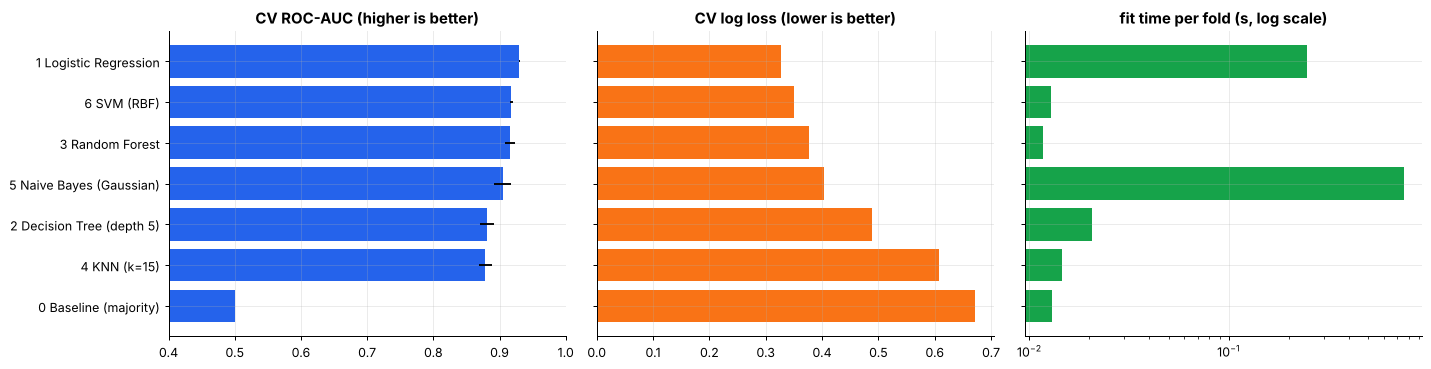

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2)); order = round1.sort_values("ROC-AUC").index
axes[0].barh(order, round1.loc[order, "ROC-AUC"], xerr=round1.loc[order, "AUC std"], color="#2563eb"); axes[0].set_xlim(0.4, 1); axes[0].set_title("CV ROC-AUC (higher is better)")
o2 = round1.sort_values("log loss", ascending=False).index; axes[1].barh(o2, round1.loc[o2, "log loss"], color="#f97316"); axes[1].set_title("CV log loss (lower is better)"); axes[1].set_yticklabels([])
axes[2].barh(round1.index, round1["fit s"], color="#16a34a"); axes[2].set_xscale("log"); axes[2].set_title("fit time per fold (s, log scale)"); axes[2].set_yticklabels([])
plt.tight_layout(); plt.show()

**Reading Round 1**

- The **baseline** shows what 'doing nothing' earns: accuracy ≈ the approval rate (~60 %), ROC-AUC = 0.5, and a log loss of ≈ 0.67 (it only knows the base rate): its F1 is respectable only because it always says 'approve'.
- **Logistic regression** is at or near the top on every metric, including **log loss**: its probabilities are the most trustworthy. The loan decision is (nearly) linear in the log-odds of good engineered features, which is exactly its home turf.
- **Random Forest** and **SVM** follow closely. **Naive Bayes** lands mid-table; the **single tree** and **KNN** trail. Look at log loss: the tree is by far the worst (its leaves emit extreme probabilities), KNN's coarse vote shares also hurt, and Naive Bayes is only mildly over-confident here (it was far worse on the cancer data of Lesson 14; how badly depends on how correlated and how noisy the features are).
- Speed: everything is fast on 2 250 rows, but the SVM with `probability=True` and the forest are the slowest.

---
## 🎛️ 3. Round 2: fair tuning

Each tunable model gets a small grid with 3-fold CV inside the training set, optimising ROC-AUC.

In [5]:
grids = {
    "1 Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "2 Decision Tree (depth 5)": {"model__max_depth": [3, 5, 7], "model__min_samples_leaf": [10, 20, 50]},
    "3 Random Forest": {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [3, 10]},
    "4 KNN (k=15)": {"model__n_neighbors": [5, 11, 21, 31], "model__weights": ["uniform", "distance"]},
    "5 Naive Bayes (Gaussian)": {"model__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]},
    "6 SVM (RBF)": {"model__C": [0.3, 1, 3], "model__gamma": ["scale", 0.01, 0.03]},
}
tuned, log = dict(contestants), []
for name, grid in grids.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(contestants[name], grid, cv=StratifiedKFold(3, shuffle=True, random_state=1), scoring="roc_auc").fit(Xtr, ytr)
    tuned[name] = gs.best_estimator_
    log.append({"model": name, "best params": {k.split("__")[-1]: v for k, v in gs.best_params_.items()}, "inner CV AUC": round(gs.best_score_, 3), "time (s)": round(time.perf_counter() - t0, 1)})
display(pd.DataFrame(log).set_index("model"))

rows = []
for name, model in tuned.items():
    r = cross_validate(model, Xtr, ytr, cv=cv, scoring=scoring)
    rows.append({"model": name, "accuracy": r["test_accuracy"].mean(), "ROC-AUC": r["test_roc_auc"].mean(), "AUC std": r["test_roc_auc"].std(), "F1": r["test_f1"].mean(),
                 "PR-AUC": r["test_pr_auc"].mean(), "log loss": -r["test_neg_log_loss"].mean()})
round2 = pd.DataFrame(rows).set_index("model"); display(round2.sort_values("ROC-AUC", ascending=False).round(3))
best = round2["ROC-AUC"].idxmax(); se = round2.loc[best, "AUC std"] / np.sqrt(5)
print(f"CV champion: {best}  | models within one standard error of it:", round2[round2['ROC-AUC'] >= round2.loc[best, 'ROC-AUC'] - se].index.tolist())

,best params,inner CV AUC,time (s)
model,,,
1 Logistic Regression,{'C': 1},0.929,0.3
2 Decision Tree (depth 5),"{'max_depth': 7, 'min_samples_leaf': 50}",0.884,0.7
3 Random Forest,"{'max_features': 0.5, 'min_samples_leaf': 3}",0.916,11.6
4 KNN (k=15),"{'n_neighbors': 31, 'weights': 'uniform'}",0.898,0.8
5 Naive Bayes (Gaussian),{'var_smoothing': 0.1},0.905,0.3
6 SVM (RBF),"{'C': 3, 'gamma': 0.01}",0.929,5.8


,accuracy,ROC-AUC,AUC std,F1,PR-AUC,log loss
model,,,,,,
1 Logistic Regression,0.861,0.930,0.001,0.888,0.949,0.327
6 SVM (RBF),0.858,0.929,0.002,0.886,0.948,0.327
3 Random Forest,0.855,0.915,0.006,0.882,0.931,0.358
5 Naive Bayes (Gaussian),0.825,0.907,0.013,0.867,0.928,0.388
4 KNN (k=15),0.814,0.893,0.008,0.859,0.916,0.432
2 Decision Tree (depth 5),0.810,0.883,0.011,0.849,0.905,0.618
0 Baseline (majority),0.604,0.500,0.000,0.753,0.604,0.671


CV champion: 1 Logistic Regression  | models within one standard error of it: ['1 Logistic Regression']


Tuning matters most where the defaults were poorly matched: the **SVM** gains ≈ 0.011 AUC (it now ties logistic regression), **KNN** gains ≈ 0.014 (a much larger k), and Naive Bayes a little; the tree, the forest and logistic regression barely move. The fold-to-fold spread of logistic regression is tiny (±0.001), which makes the one-standard-error rule very strict: the SVM, 0.001 behind, is for all practical purposes **tied** with it. When models tie, prefer the simplest, fastest, most explainable.

---
## 🏆 4. The final: held-out test set and ROC curves

The audit on the 750 locked-away applications (in a real project you'd score only the chosen model).

,accuracy,ROC-AUC,F1,PR-AUC,log loss
model,,,,,
1 Logistic Regression,0.864,0.928,0.892,0.950,0.327
6 SVM (RBF),0.864,0.927,0.892,0.949,0.328
3 Random Forest,0.841,0.909,0.873,0.931,0.366
5 Naive Bayes (Gaussian),0.825,0.909,0.869,0.935,0.383
4 KNN (k=15),0.808,0.898,0.857,0.921,0.426
2 Decision Tree (depth 5),0.840,0.877,0.871,0.885,0.809
0 Baseline (majority),0.604,0.500,0.753,0.604,0.671


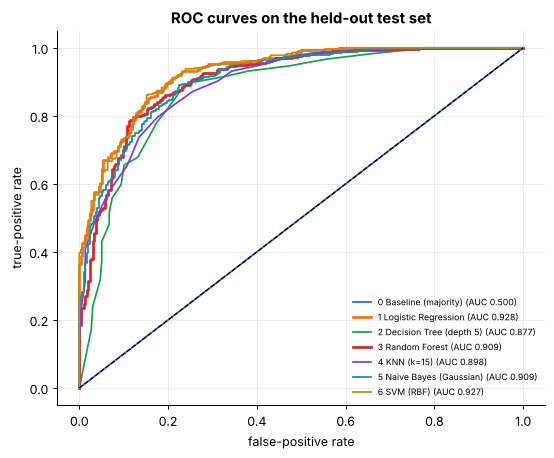

In [6]:
rows, curves = [], {}
for name, model in tuned.items():
    model.fit(Xtr, ytr); p = model.predict_proba(Xte)[:, 1]; curves[name] = roc_curve(yte, p)
    rows.append({"model": name, "accuracy": accuracy_score(yte, p >= .5), "ROC-AUC": roc_auc_score(yte, p), "F1": f1_score(yte, p >= .5), "PR-AUC": average_precision_score(yte, p), "log loss": log_loss(yte, p)})
final = pd.DataFrame(rows).set_index("model"); display(final.sort_values("ROC-AUC", ascending=False).round(3))
fig, ax = plt.subplots(figsize=(7, 5.4))
for name, (f, t, _) in curves.items(): ax.plot(f, t, lw=2.2 if "Logistic" in name or "Forest" in name else 1.4, label=f"{name} (AUC {final.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate"); ax.legend(fontsize=7, loc="lower right"); ax.set_title("ROC curves on the held-out test set"); plt.show()

The good models' ROC curves nearly overlap: differences of ~0.01 AUC are well within the sampling noise of a 750-row test set. Keep that humility in mind when you read any leaderboard.

---
## 📏 5. Can we trust the probabilities?

For cost-based decisions, probability *quality* matters as much as ranking. Reliability curves and log loss tell us which models speak honestly:

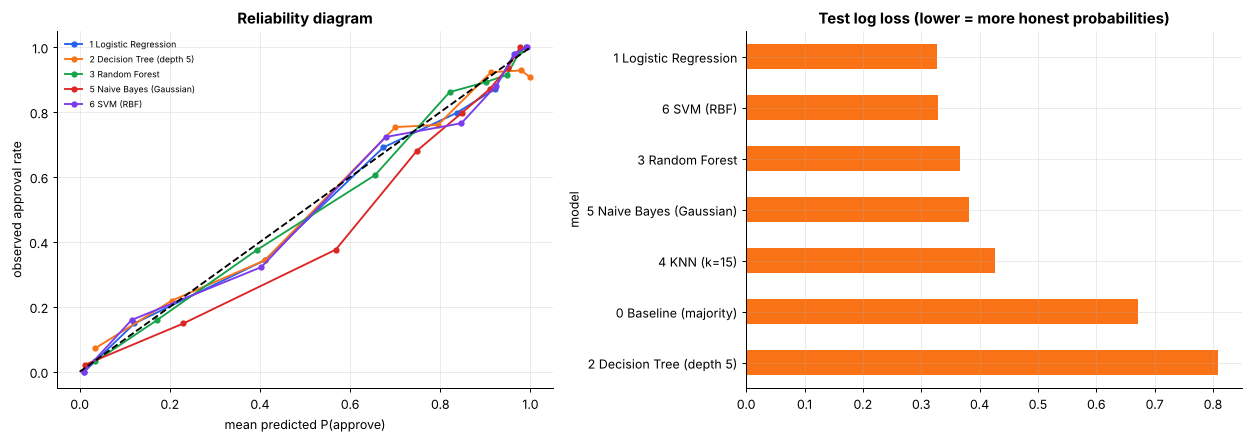

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in ["1 Logistic Regression", "2 Decision Tree (depth 5)", "3 Random Forest", "5 Naive Bayes (Gaussian)", "6 SVM (RBF)"]:
    p = tuned[name].predict_proba(Xte)[:, 1]; pt, pp = calibration_curve(yte, p, n_bins=8, strategy="quantile"); axes[0].plot(pp, pt, "o-", ms=4, label=name)
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_xlabel("mean predicted P(approve)"); axes[0].set_ylabel("observed approval rate"); axes[0].legend(fontsize=7); axes[0].set_title("Reliability diagram")
final["log loss"].sort_values(ascending=False).plot.barh(ax=axes[1], color="#f97316"); axes[1].set_title("Test log loss (lower = more honest probabilities)")
plt.tight_layout(); plt.show()

Logistic regression and the SVM (via Platt scaling) have the lowest log loss and track the diagonal best; the forest is a little timid at the extremes; Naive Bayes is somewhat over-confident (mildly here, because the labels are noisy enough to limit the damage of double-counting); and the **single tree is the least honest by far**: coarse, erratic probabilities with a log loss more than double the best. If you need to *calibrate* a model, wrap it in `CalibratedClassifierCV(method='isotonic' or 'sigmoid')`.

---
## 💰 6. From costs to a threshold: and the savings

Business input: approving an applicant who should have been rejected (a **false approval**, FP) costs the bank **5 units**; rejecting a deserving applicant (a **false rejection**, FN) costs **1 unit** (lost margin). For calibrated probabilities the optimal rule is: approve when $\hat p>\dfrac{c_{FP}}{c_{FP}+c_{FN}}=\dfrac56\approx0.83$: we should be *much* pickier than 0.5.

We choose the threshold using **cross-validated predictions on the training set only** (never the test set), then audit the savings on the test set.

Champion on test AUC: 1 Logistic Regression
threshold from cost minimisation on CV predictions: τ* = 0.77 (theory for calibrated probs: 0.83)
TEST cost at τ = 0.50 : 386   |   TEST cost at τ* = 0.77: 278   ->  saving 28%


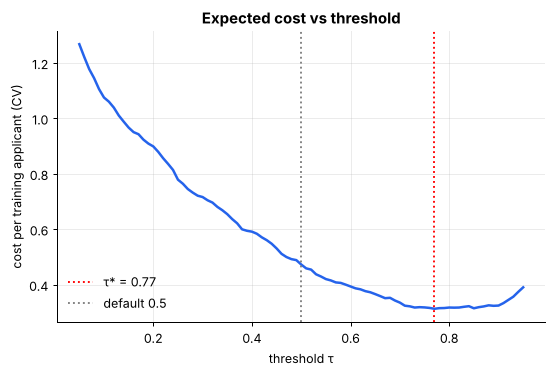

In [8]:
c_fp, c_fn = 5, 1
champ_name = final["ROC-AUC"].idxmax(); print("Champion on test AUC:", champ_name)
champ = tuned[champ_name]
oof = cross_val_predict(champ, Xtr, ytr, cv=cv, method="predict_proba")[:, 1]          # honest out-of-fold probabilities

def total_cost(y_true, p, tau):
    pred = p >= tau; fp = np.sum(pred & (y_true == 0)); fn = np.sum(~pred & (y_true == 1)); return c_fp * fp + c_fn * fn

taus = np.linspace(0.05, 0.95, 91); costs = [total_cost(ytr.values, oof, t) for t in taus]
tau_star = taus[int(np.argmin(costs))]
print(f"threshold from cost minimisation on CV predictions: τ* = {tau_star:.2f} (theory for calibrated probs: {c_fp / (c_fp + c_fn):.2f})")

champ.fit(Xtr, ytr); p_te = champ.predict_proba(Xte)[:, 1]
cost_default, cost_tuned = total_cost(yte.values, p_te, 0.5), total_cost(yte.values, p_te, tau_star)
print(f"TEST cost at τ = 0.50 : {cost_default}   |   TEST cost at τ* = {tau_star:.2f}: {cost_tuned}   ->  saving {100 * (cost_default - cost_tuned) / cost_default:.0f}%")
plt.plot(taus, np.array(costs) / len(ytr), lw=2); plt.axvline(tau_star, color="r", ls=":", label=f"τ* = {tau_star:.2f}"); plt.axvline(0.5, color="gray", ls=":", label="default 0.5"); plt.xlabel("threshold τ"); plt.ylabel("cost per training applicant (CV)"); plt.legend(); plt.title("Expected cost vs threshold"); plt.show()

In [9]:
for tau in [0.5, tau_star]:
    pred = p_te >= tau; tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    print(f"τ={tau:.2f}: approve {pred.sum():>3} of {len(pred)} | false approvals {fp:>3} (cost {c_fp * fp}) | false rejections {fn:>3} (cost {c_fn * fn}) | precision {tp / (tp + fp):.3f} | recall {tp / (tp + fn):.3f}")

τ=0.50: approve 493 of 750 | false approvals  71 (cost 355) | false rejections  31 (cost 31) | precision 0.856 | recall 0.932
τ=0.77: approve 379 of 750 | false approvals  34 (cost 170) | false rejections 108 (cost 108) | precision 0.910 | recall 0.762


> 🔑 **Key idea.**
>
> The same model, a different threshold, a very different business outcome: often a far bigger effect than choosing between two good algorithms. Note the trade: we approve fewer applicants and reject more deserving ones (higher FN cost) but avoid many costly bad approvals. Always present the cost matrix assumptions to stakeholders: the 'best' threshold is only as good as those numbers.

---
## 🧭 7. A decision guide for classification

Phase 4's classification toolkit in one table (★ = strength).

| Algorithm | Interpretability | Probability quality | Structure it fits | Reach for it when… |
|---|---|---|---|---|
| **Logistic Regression** | ★★★★★ (odds ratios) | ★★★★★ honest | linear in log-odds | Default first model; regulated settings; probabilities matter; small/medium data |
| **Decision Tree** | ★★★★★ (rules) | ★★ coarse | thresholds, interactions | Need transparent rules; quick exploration; as a teaching/baseline model |
| **Random Forest** | ★★ (importances) | ★★★ timid | non-linear, interactions | Strong default for tabular data with mixed types and little tuning |
| **KNN** | ★★★★ (neighbours) | ★★ coarse | local structure | Small data, meaningful distance (images/embeddings), quick baseline; avoid with many features/imbalance |
| **Naive Bayes** | ★★★★ (word weights) | ★★ often over-confident | assumes independence | Text, tiny datasets, streaming/online learning, instant training |
| **SVM (RBF / linear)** | ★ (kernel) / ★★★ (linear) | ★★★ via Platt | smooth non-linear | Small/medium, high-dimensional data; linear SVM for large sparse text |

**A practical routine for any classification problem**

1. **Frame** the costs and the metric first (accuracy? recall? expected cost?). Check class balance.
2. **Baseline** (`DummyClassifier`) + **logistic regression** on scaled/encoded features: fast, honest, interpretable.
3. Try a **random forest**: if it's much better → non-linearity/interactions matter; engineer features or keep the forest.
4. Consider **SVM** (small/medium n), **KNN** (local structure), **Naive Bayes** (text/tiny data) when their strengths match.
5. Compare with **stratified CV**, several metrics, and the one-standard-error rule. Tie → choose simple.
6. **Choose the threshold from costs** using out-of-fold predictions; calibrate if probabilities feed decisions.
7. Audit once on the **test set**, check errors by **segment** (and fairness), then document assumptions.

---
### 🧩 Problem 1: Write a reusable classification leaderboard  ⭐

Write `leaderboard(models, X, y, cv)` that returns a DataFrame (indexed by model name) with columns `roc_auc`, `f1`, `log_loss` (positive!) from `cross_validate` and sorted by `roc_auc` descending. Apply it to `trio = {k: contestants[k] for k in ['1 Logistic Regression', '3 Random Forest', '4 KNN (k=15)']}` and store the result in `lb`.

In [10]:
# ✅ SOLUTION
def leaderboard(models, X, y, cv):
    rows = []
    for name, m in models.items():
        r = cross_validate(m, X, y, cv=cv, scoring={"roc_auc": "roc_auc", "f1": "f1", "neg_log_loss": "neg_log_loss"})
        rows.append({"model": name, "roc_auc": r["test_roc_auc"].mean(), "f1": r["test_f1"].mean(), "log_loss": -r["test_neg_log_loss"].mean()})
    return pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)

trio = {k: contestants[k] for k in ["1 Logistic Regression", "3 Random Forest", "4 KNN (k=15)"]}
lb = leaderboard(trio, Xtr, ytr, cv); display(lb.round(3))

,roc_auc,f1,log_loss
model,,,
1 Logistic Regression,0.930,0.888,0.327
3 Random Forest,0.916,0.885,0.376
4 KNN (k=15),0.879,0.847,0.489


**Why this works.** A function around `cross_validate` is a tool you'll reuse in every project; keeping the metric definitions in one place prevents inconsistent comparisons.

In [11]:
check("3 models × 3 metrics", lambda: lb.shape == (3, 3))
check("sorted by AUC, best first", lambda: lb["roc_auc"].is_monotonic_decreasing)
check("log loss is positive", lambda: (lb["log_loss"] > 0).all())
check("logistic regression beats KNN on AUC", lambda: lb.loc["1 Logistic Regression", "roc_auc"] > lb.loc["4 KNN (k=15)", "roc_auc"])

✅  3 models × 3 metrics
✅  sorted by AUC, best first
✅  log loss is positive
✅  logistic regression beats KNN on AUC


---
### 🧩 Problem 2: The optimal threshold for known costs  ⭐⭐

Write `best_threshold(y_true, p, c_fp, c_fn)` that scans `np.linspace(0.01, 0.99, 197)` and returns the threshold minimising `c_fp·FP + c_fn·FN` (first minimum on ties). Test it on simulated, perfectly **calibrated** probabilities: `rng = np.random.default_rng(0); p_sim = rng.random(200000); y_sim = (rng.random(200000) < p_sim).astype(int)`. Store `tau_5_1` for (c_fp=5, c_fn=1), `tau_1_1` for (1, 1) and `tau_1_9` for (1, 9). Theory: c_fp/(c_fp+c_fn).

In [12]:
# ✅ SOLUTION
def best_threshold(y_true, p, c_fp, c_fn):
    ts = np.linspace(0.01, 0.99, 197); costs = []
    for t in ts:
        pred = p >= t; costs.append(c_fp * np.sum(pred & (y_true == 0)) + c_fn * np.sum(~pred & (y_true == 1)))
    return ts[int(np.argmin(costs))]

rng = np.random.default_rng(0); p_sim = rng.random(200000); y_sim = (rng.random(200000) < p_sim).astype(int)
tau_5_1 = best_threshold(y_sim, p_sim, 5, 1); tau_1_1 = best_threshold(y_sim, p_sim, 1, 1); tau_1_9 = best_threshold(y_sim, p_sim, 1, 9)
print(tau_5_1, tau_1_1, tau_1_9)

0.8250000000000001 0.5 0.09999999999999999


**Why this works.** With calibrated probabilities the empirical optimum reproduces the closed-form c_FP/(c_FP+c_FN): a lovely sanity check on your cost reasoning. With uncalibrated models you must find the threshold empirically (as in Section 6).

In [13]:
check("(5,1): near 5/6 ≈ 0.833", lambda: abs(tau_5_1 - 5 / 6) < 0.02)
check("(1,1): near 0.5", lambda: abs(tau_1_1 - 0.5) < 0.02)
check("(1,9): near 0.1", lambda: abs(tau_1_9 - 0.1) < 0.02)

✅  (5,1): near 5/6 ≈ 0.833
✅  (1,1): near 0.5
✅  (1,9): near 0.1


---
### 🧩 Problem 3: Rank the tuned models on the test set  ⭐⭐

Using the lesson's `tuned` models (already fit on `Xtr` in Section 4) compute each model's test ROC-AUC and store the results in a Series `test_auc` (index = model name, sorted descending). Set `top` (name of the best), `bottom_real` (name of the worst model **excluding** the baseline `'0 Baseline (majority)'`) and `spread` = best − worst AUC among the real models.

In [14]:
# ✅ SOLUTION
test_auc = pd.Series({n: roc_auc_score(yte, m.predict_proba(Xte)[:, 1]) for n, m in tuned.items()}).sort_values(ascending=False)
real = test_auc.drop("0 Baseline (majority)")
top = test_auc.index[0]; bottom_real = real.index[-1]; spread = real.max() - real.min()
print(test_auc.round(3).to_dict(), top, bottom_real, round(spread, 3))

{'1 Logistic Regression': 0.928, '6 SVM (RBF)': 0.927, '3 Random Forest': 0.909, '5 Naive Bayes (Gaussian)': 0.909, '4 KNN (k=15)': 0.898, '2 Decision Tree (depth 5)': 0.877, '0 Baseline (majority)': 0.5} 1 Logistic Regression 2 Decision Tree (depth 5) 0.051


**Why this works.** The baseline's AUC is exactly 0.5 (constant scores). The real models span ~0.1 AUC from best to worst; the top few are separated by less than the test-set noise.

In [15]:
check("baseline AUC is 0.5", lambda: abs(test_auc["0 Baseline (majority)"] - 0.5) < 1e-9)
check("sorted descending", lambda: test_auc.is_monotonic_decreasing)
check("every real model beats the baseline", lambda: (test_auc.drop("0 Baseline (majority)") > 0.6).all())
check("spread among real models is below 0.12", lambda: spread < 0.12)

✅  baseline AUC is 0.5
✅  sorted descending
✅  every real model beats the baseline
✅  spread among real models is below 0.12


---
### 🧩 Problem 4: Add gradient boosting to the tournament  ⭐⭐

Build `HistGradientBoostingClassifier(random_state=0)` with the shared `build(...)`, compute its 5-fold CV ROC-AUC with the lesson's `cv` (`cross_validate(..., scoring='roc_auc')`) and store it as `hgb_auc`. Store `hgb_rank` = its rank (1 = best) among `round1['ROC-AUC']` plus itself, and `beats_logreg = hgb_auc > round1.loc['1 Logistic Regression', 'ROC-AUC']`.

In [16]:
# ✅ SOLUTION
hgb_cv = cross_validate(build(HistGradientBoostingClassifier(random_state=0)), Xtr, ytr, cv=cv, scoring="roc_auc"); hgb_auc = hgb_cv["test_score"].mean()
all_auc = pd.concat([round1["ROC-AUC"], pd.Series({"hgb": hgb_auc})]); hgb_rank = int((all_auc > hgb_auc).sum() + 1); beats_logreg = bool(hgb_auc > round1.loc["1 Logistic Regression", "ROC-AUC"])
print(round(hgb_auc, 3), hgb_rank, beats_logreg)

0.912 4 False


**Why this works.** Boosted trees are a great default on messy tabular data, but when the true log-odds are (almost) linear in well-engineered features, logistic regression is hard to beat, and far simpler to explain and audit.

In [17]:
check("gradient boosting is competitive (AUC > 0.9)", lambda: hgb_auc > 0.9)
check("it ranks in the top 4 of 8", lambda: hgb_rank <= 4)
check("logistic regression still wins on this near-linear problem", lambda: beats_logreg is False)

✅  gradient boosting is competitive (AUC > 0.9)
✅  it ranks in the top 4 of 8
✅  logistic regression still wins on this near-linear problem


---
### 🧩 Problem 5: Which model speaks honestly?  ⭐⭐

Compute the **test log loss** of every tuned *real* model (exclude the baseline) → Series `ll` (sorted ascending). Store `most_honest` (lowest log loss) and `worst_probabilities` (highest), and `ll_ratio` = highest / lowest.

In [18]:
# ✅ SOLUTION
ll = pd.Series({n: log_loss(yte, m.predict_proba(Xte)[:, 1]) for n, m in tuned.items() if not n.startswith("0")}).sort_values()
most_honest, worst_probabilities = ll.index[0], ll.index[-1]; ll_ratio = ll.iloc[-1] / ll.iloc[0]
print(ll.round(3).to_dict(), most_honest, worst_probabilities, round(ll_ratio, 2))

{'1 Logistic Regression': 0.327, '6 SVM (RBF)': 0.328, '3 Random Forest': 0.366, '5 Naive Bayes (Gaussian)': 0.383, '4 KNN (k=15)': 0.426, '2 Decision Tree (depth 5)': 0.809} 1 Logistic Regression 2 Decision Tree (depth 5) 2.47


**Why this works.** Log loss punishes confident mistakes severely. A depth-7 tree with small leaves emits near-0/1 probabilities from tiny groups of applicants, so its occasional confident errors are very costly: its log loss is more than double the best model's even though its accuracy (0.84) looks fine. (Naive Bayes, the usual suspect, is only mildly over-confident on this data.)

In [19]:
check("baseline excluded (6 real models)", lambda: len(ll) == 6)
check("logistic regression is among the two most honest models", lambda: "1 Logistic Regression" in ll.index[:2])
check("the single decision tree has the worst probabilities", lambda: worst_probabilities == "2 Decision Tree (depth 5)")
check("the gap is large (ratio > 1.5)", lambda: ll_ratio > 1.5)

✅  baseline excluded (6 real models)
✅  logistic regression is among the two most honest models
✅  the single decision tree has the worst probabilities
✅  the gap is large (ratio > 1.5)


---
### 🧩 Problem 6: How much does the threshold save?  ⭐⭐⭐

Use `champ` (already fit), `p_te`, `tau_star` and `total_cost` from Section 6. Compute the test costs under a *different* cost matrix: a false approval costs **3**, a false rejection costs **2**: at τ = 0.5 (`cost_a`) and at the *old* `tau_star` (`cost_b`). Then re-derive the best threshold for the **new** costs from the out-of-fold probabilities `oof` and training labels (scan `taus`), store `tau_new`, and its test cost `cost_c`. Set `old_threshold_misleads = cost_c < cost_b`.

In [20]:
# ✅ SOLUTION
def cost_new(y_true, p, tau):
    pred = p >= tau; return 3 * np.sum(pred & (y_true == 0)) + 2 * np.sum(~pred & (y_true == 1))

cost_a = cost_new(yte.values, p_te, 0.5); cost_b = cost_new(yte.values, p_te, tau_star)
tau_new = taus[int(np.argmin([cost_new(ytr.values, oof, t) for t in taus]))]; cost_c = cost_new(yte.values, p_te, tau_new); old_threshold_misleads = bool(cost_c < cost_b)
print(cost_a, cost_b, round(tau_new, 2), cost_c, old_threshold_misleads)

275 318 0.54 271 True


**Why this works.** A threshold is not a property of the model: it encodes a cost matrix. When the economics change (here from 5:1 to 3:2) the old τ* (≈ 0.8) becomes too strict and wastes good applicants: recompute it from fresh costs.

In [21]:
check("new threshold is near the theoretical 3/5 = 0.6 (0.45-0.75)", lambda: 0.45 < tau_new < 0.75)
check("the re-derived threshold costs less than the stale one", lambda: old_threshold_misleads)
check("and no more than the naive 0.5 threshold (+5% tolerance)", lambda: cost_c <= cost_a * 1.05)

✅  new threshold is near the theoretical 3/5 = 0.6 (0.45-0.75)
✅  the re-derived threshold costs less than the stale one
✅  and no more than the naive 0.5 threshold (+5% tolerance)


---
## 🧠 Check Your Understanding
Answer each question in your head (or on paper) *before* opening the answer.

**Q1.** Why must the cost-based threshold be chosen with *out-of-fold* training predictions rather than the test set?

<details><summary>👀 Show answer</summary>

Choosing it on the test set would let the test data influence a modelling decision, so the final cost estimate would be optimistic; out-of-fold predictions are honest yet use only training data.

</details>

**Q2.** Two models differ by 0.004 test AUC on 750 rows. What do you conclude?

<details><summary>👀 Show answer</summary>

Nothing: the difference is within sampling noise. Decide on simplicity, speed, interpretability and calibration.

</details>

**Q3.** A model has accuracy 0.84 but the worst log loss in the table. What does that tell you?

<details><summary>👀 Show answer</summary>

Its hard decisions are fine but its probabilities are over-confident (or coarse): when it is wrong it is very sure. Here it is the single decision tree; Naive Bayes can behave similarly when features are strongly correlated.

</details>

**Q4.** False approvals cost 5× more than false rejections. Should the approval threshold be above or below 0.5, and roughly where?

<details><summary>👀 Show answer</summary>

Above: approve only when quite sure: about 5/(5+1) ≈ 0.83 for calibrated probabilities.

</details>

**Q5.** When would you rather ship logistic regression than a slightly more accurate random forest?

<details><summary>👀 Show answer</summary>

When explainability/auditability (regulation), calibrated probabilities, small footprint, or maintainability matter more than a negligible accuracy gain: as with credit scoring.

</details>

---
## 🔁 Recap

- A fair tournament: shared pipeline, identical stratified folds, several metrics, a baseline, comparable tuning, one final test.
- On this near-linear loan problem, logistic regression is hard to beat on accuracy *and* probability honesty; forest/SVM are close; tree/KNN/NB trail.
- Judge probabilities with log loss and reliability curves: logistic regression and the Platt-scaled SVM are the most honest; a single tree is the least.
- Business costs, not 0.5, set the threshold: τ* ≈ c_FP/(c_FP + c_FN) for calibrated models; choose it on out-of-fold predictions and recompute when costs change.
- Use the decision guide and the 7-step routine to pick a classifier from the data and the constraints.

### ➡️ Up next: **Algorithm Selection Guide**
Open `17_Algorithm_Selection_Guide.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀